# SmartPick AI - PJ1 Mobile Recommender
**Samsung Innovation Campus | Generative AI | Chapter 5**

**Problem:** A phone shop filters only by price and RAM, but a student, a gamer and a grandmother want very different phones.
**Solution:** Turn each lifestyle (persona) into weights, score every phone with a weighted score, and show the top 5 per persona.

Steps: 1 Problem -> 2 Data -> 3 Design -> 4 Build -> 5 Present. Run the cells from top to bottom.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from data_cleaning import clean_mobile_data
from recommendation import PERSONA_WEIGHTS, get_recommendations, generate_explanation
print('Setup complete')

Setup complete


## 2. Data - open, clean, explore

In [2]:
raw = pd.read_excel('../datasets/sic_mobile_spec_PJ1.xlsx')
print(raw.shape)
raw.head()

(413, 11)


,name,rating,price,camera,display_type,display_size,battery,storage,ram,weight,processor
0,Voltix Hyper67 5G (256 GB),4.9,$1000,200,HD+ AMOLED,6.7,4700,256GB,4,190.0,Dimensity9000Processor
1,Orion Edge12 5G (512 GB),4.6,$1200,200,HD+ AMOLED,6.8,4700,512GB,12,205.0,Snapdragon8Gen2Processor
2,Celesto Ultra61 5G (1TB),4.3,1200,200,HD+ AMOLED,6.8,5000,1TB,12,234.0,Snapdragon8Gen2Processor
3,NeoPhone X32 Neo (128 GB),4.0,300,200,AMOLED,6.8,5000,128,3,198.0,Gen8
4,Celesto Plus33 SE (128 GB),4.3,280,200,AMOLED,6.6,4500,128,6,185.0,not mentioned


In [3]:
# Messy columns found in the raw data
print('price formats  :', raw['price'].astype(str).str.replace(r'\d', '9', regex=True).unique())
print('storage values :', raw['storage'].astype(str).unique())
print('processor      :', (raw['processor'] == 'not mentioned').sum(), 'of', len(raw), "rows say 'not mentioned'")

price formats  : <ArrowStringArray>
['$9999', '9999', '999', '99']
Length: 4, dtype: str
storage values : <ArrowStringArray>
['256GB', '512GB', '1TB', '128', '256', '512', '64', '32']
Length: 8, dtype: str
processor      : 276 of 413 rows say 'not mentioned'


In [4]:
df = clean_mobile_data('../datasets/sic_mobile_spec_PJ1.xlsx')
df[['name','price','ram','storage_gb','battery','camera','processor_cleaned','processor_score']].head()

,name,price,ram,storage_gb,battery,camera,processor_cleaned,processor_score
0,Voltix Hyper67 5G (256 GB),1000.0,4,256,4700,200,Dimensity9000Processor,1.0
1,Orion Edge12 5G (512 GB),1200.0,12,512,4700,200,Snapdragon8Gen2Processor,1.0
2,Celesto Ultra61 5G (1TB),1200.0,12,1024,5000,200,Snapdragon8Gen2Processor,1.0
3,NeoPhone X32 Neo (128 GB),300.0,3,128,5000,200,Gen8,0.8
4,Celesto Plus33 SE (128 GB),280.0,6,128,4500,200,Not Mentioned,0.3


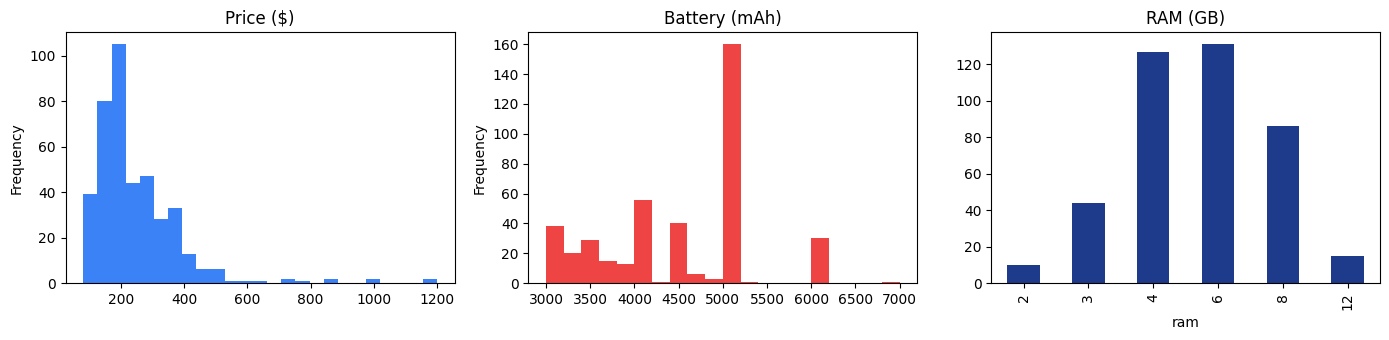

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
df['price'].plot.hist(bins=25, ax=ax[0], color='#3B82F6'); ax[0].set_title('Price ($)')
df['battery'].plot.hist(bins=20, ax=ax[1], color='#EF4444'); ax[1].set_title('Battery (mAh)')
df['ram'].value_counts().sort_index().plot.bar(ax=ax[2], color='#1E3A8A'); ax[2].set_title('RAM (GB)')
plt.tight_layout(); plt.show()

## 3. Design - turn a lifestyle into weights
Each persona has weights that add up to 100%. Prices are flipped so cheaper phones score higher, and every column is Min-Max scaled to 0-1.

In [6]:
weights = pd.DataFrame(PERSONA_WEIGHTS).fillna(0).T
weights['TOTAL'] = weights.sum(axis=1)
assert np.allclose(weights['TOTAL'], 1.0), 'Weights must add to 100%'
(weights * 100).round(0).astype(int).astype(str) + '%'

,price,battery,ram,storage_gb,processor_score,camera,TOTAL
Student,40%,25%,15%,10%,10%,0%,100%
Gamer,5%,20%,30%,10%,35%,0%,100%
Content Creator,5%,5%,15%,20%,15%,40%,100%
Business Professional,10%,30%,20%,10%,30%,0%,100%
Senior Citizen,40%,30%,15%,10%,5%,0%,100%


## 4. Build - score the phones

In [7]:
top5 = {p: get_recommendations(df, p) for p in PERSONA_WEIGHTS}
top5['Student'][['name','final_score','price','ram','storage_gb','battery','camera','processor_cleaned']]

,name,final_score,price,ram,storage_gb,battery,camera,processor_cleaned
389,Orion Prime12 SE (256 GB),70.293779,240.0,12,256,4400,12,Snapdragon888
382,Orion Note57 SE (512 GB),69.302995,340.0,12,512,4400,12,Snapdragon888
283,Hyperon Edge40 Neo (64 GB),67.072581,140.0,4,64,6000,12,"Dimensity1080,"
269,Voltix Ultra29 Pro (128 GB),66.789171,170.0,6,128,6000,48,Heilo80P
317,Hyperon One44 Pro (128 GB),66.396313,320.0,8,128,7000,13,Not Mentioned


## 5. Present - top 5 for every persona

In [8]:
for p, r in top5.items():
    print(f'\n=== {p} ===')
    for i, (_, row) in enumerate(r.iterrows(), 1):
        print(f"#{i} {row['name']}  ({row['final_score']:.1f}/100, ${row['price']:.0f})")
        print('   ', generate_explanation(row, p))


=== Student ===
#1 Orion Prime12 SE (256 GB)  (70.3/100, $240)
    Selected for its budget-friendly price of $240, reliable 12GB RAM for multitasking.
#2 Orion Note57 SE (512 GB)  (69.3/100, $340)
    Selected for its budget-friendly price of $340, reliable 12GB RAM for multitasking.
#3 Hyperon Edge40 Neo (64 GB)  (67.1/100, $140)
    Selected for its budget-friendly price of $140, long-lasting 6000 mAh battery for all-day classes.
#4 Voltix Ultra29 Pro (128 GB)  (66.8/100, $170)
    Selected for its budget-friendly price of $170, long-lasting 6000 mAh battery for all-day classes, reliable 6GB RAM for multitasking.
#5 Hyperon One44 Pro (128 GB)  (66.4/100, $320)
    Selected for its budget-friendly price of $320, long-lasting 7000 mAh battery for all-day classes, reliable 8GB RAM for multitasking.

=== Gamer ===
#1 Celesto Ultra61 5G (1TB)  (85.0/100, $1200)
    Selected for its high-performance processor for lag-free gaming, heavy-duty 12GB RAM, robust 5000 mAh battery.
#2 Celesto Xt

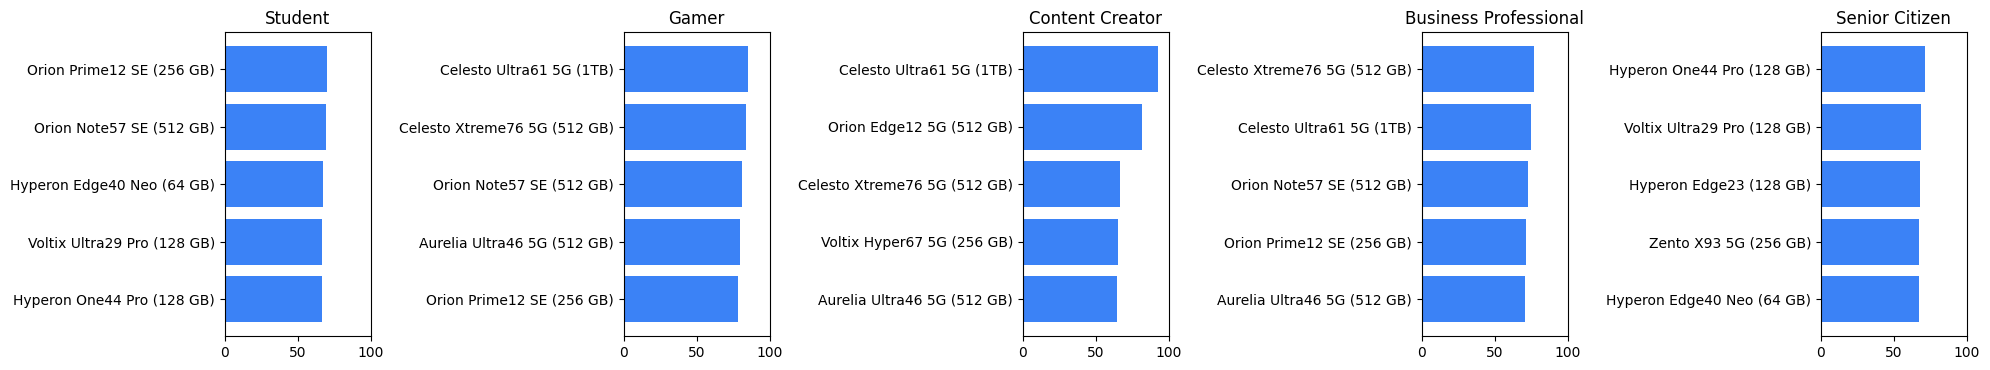

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8), sharex=True)
for ax, (p, r) in zip(axes, top5.items()):
    ax.barh(r['name'].iloc[::-1], r['final_score'].iloc[::-1], color='#3B82F6')
    ax.set_title(p); ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

## Check: do the personas really give different answers?

In [10]:
names = {p: set(r['name']) for p, r in top5.items()}
overlap = pd.DataFrame({a: {b: len(names[a] & names[b]) for b in names} for a in names})
print('Phones shared between two personas top-5 lists (diagonal = 5):')
overlap

Phones shared between two personas top-5 lists (diagonal = 5):


,Student,Gamer,Content Creator,Business Professional,Senior Citizen
Student,5,2,0,2,3
Gamer,2,5,3,5,0
Content Creator,0,3,5,3,0
Business Professional,2,5,3,5,0
Senior Citizen,3,0,0,0,5


In [11]:
# Filters: budget <= $300, RAM >= 6GB, storage >= 128GB
f = get_recommendations(df, 'Student', max_budget=300, min_ram=6, min_storage=128)
assert (f['price'] <= 300).all() and (f['ram'] >= 6).all() and (f['storage_gb'] >= 128).all()
f[['name','final_score','price','ram','storage_gb']]

,name,final_score,price,ram,storage_gb
389,Orion Prime12 SE (256 GB),58.095238,240.0,12,256
18,Zento X93 5G (256 GB),56.904762,220.0,12,256
269,Voltix Ultra29 Pro (128 GB),54.047619,170.0,6,128
148,Zento Plus77 (256 GB),52.500000,180.0,8,256
147,Celesto Edge38 Pro (256 GB),52.500000,180.0,8,256


## Reflection (for the presentation)
- **Key decisions:** see the weight table above and the processor tiers in `prompts/scoring_template.md`.
- **One thing the AI got wrong:** see `outputs/evaluation_log.md`.
- **Next improvements:** use the `rating` column, add a brand filter, show real phone photos.